Construir un HOE


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from optiland.optic import Optic
from optiland.materials import IdealMaterial, Material
from optiland.analysis import SpotDiagram
from scipy.ndimage import zoom

In [8]:
lente = Optic(name="Lente1")
lente.surfaces.add(index=0,thickness = np.inf)
lente.surfaces.add(index = 1,radius = 50.0,thickness = 1, material = 'N-BK7',is_stop=True)
lente.surfaces.add(index = 2, radius = -50.0,thickness = 45.0)
lente.surfaces.add(index=3)

In [9]:
lente.set_aperture(aperture_type='EPD',value = 10.0)
lente.fields.set_type(field_type = 'angle')
lente.fields.add(y=0)
lente.wavelengths.add(value=0.55, is_primary=True)

╒════╤═════════════════╤═══════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type            │ Comment   │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═════════════════╪═══════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar          │           │      inf │         inf │ Air        │       0 │        5        │
│  1 │ Stop - Standard │           │       50 │           1 │ N-BK7      │       0 │        5        │
│  2 │ Standard        │           │      -50 │          45 │ Air        │       0 │        4.96585  │
│  3 │ Planar          │           │      inf │         nan │ Air        │       0 │        0.315087 │
╘════╧═════════════════╧═══════════╧══════════╧═════════════╧════════════╧═════════╧═════════════════╛



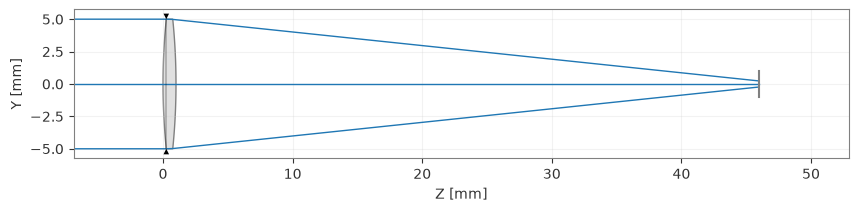

focal: 48.37912376943149 mm


In [13]:
lente.info()
lente.draw()
print('focal:',lente.paraxial.f2(), 'mm')
lente.draw3D(num_rays=100)

In [17]:
lente_foto = Optic(name='foto')
lente_foto.surfaces.add(index=0, thickness=150.0)          
lente_foto.surfaces.add(index=1, radius=50.0, thickness=1, material='N-BK7', is_stop=True)
lente_foto.surfaces.add(index=2, radius=-50.0, thickness=70.0)     
lente_foto.surfaces.add(index=3)
lente_foto.set_aperture(aperture_type = 'EPD', value =10.0)
lente_foto.fields.set_type(field_type='object_height')
lente_foto.fields.add(y=0)
lente_foto.fields.add(y=10.0)
lente_foto.wavelengths.add(value=0.55, is_primary=True)

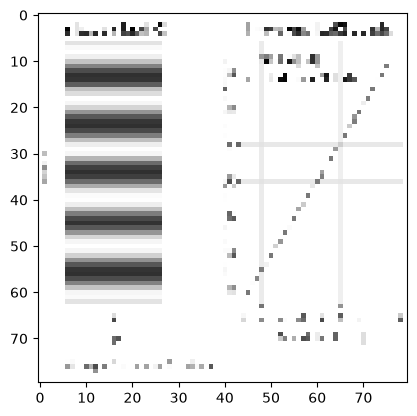

In [26]:
foto = plt.imread('hoe_1_grabacion.png')[:,:,:3].mean(axis=2)
foto = zoom(foto, (80/ foto.shape[0],80/foto.shape[1]), order=1)
alto,ancho = foto.shape
plt.imshow(foto, cmap='gray'); plt.show()


In [ ]:
HX,Hy = np.meshgrid(np.linspace(-1,1,ancho),np.linspace(-1,1,alto))
n = 20
rng = np.random.default_rng(0)
r = np.sqrt(rng.random(HX.size*n))
a = 2* np.pi*rng.random(HX.size*n)
